--- Evaluation ---
L1 -> Precision: 0.9857, Recall: 0.9718, F1: 0.9787
L2 -> Precision: 0.9722, Recall: 0.9859, F1: 0.9790


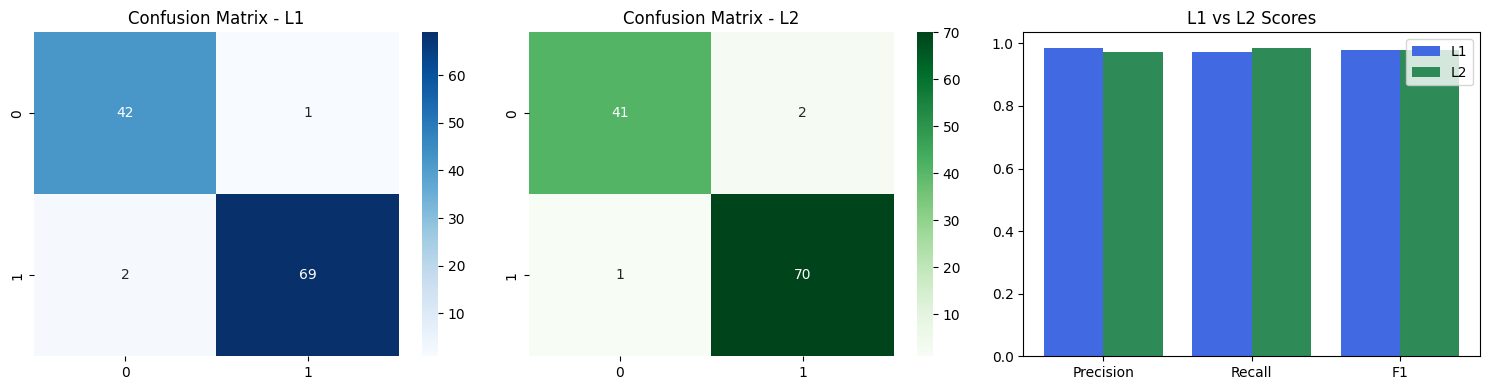


Top Features (L1):
 worst area: -2.7882
 radius error: -2.4951
 mean concave points: -2.3992
 worst texture: -1.8532
 worst concavity: -1.3185

Top Features (L2):
 worst texture: -1.3506
 radius error: -1.2682
 worst symmetry: -1.2082
 mean concave points: -1.1198
 worst concavity: -0.9431


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Dataset
data = load_breast_cancer()

X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train L1 and L2 Models
m_l1 = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    max_iter=1000
).fit(X_train, y_train)

m_l2 = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    max_iter=1000
).fit(X_train, y_train)

# Predictions
y_pred_l1 = m_l1.predict(X_test)
y_pred_l2 = m_l2.predict(X_test)


# Evaluation metrics
def get_metrics(name, y_true, y_pred):

    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    f = f1_score(y_true, y_pred)

    print(
        f"{name} -> Precision: {p:.4f}, "
        f"Recall: {r:.4f}, F1: {f:.4f}"
    )

    return [p, r, f]


print("--- Evaluation ---")

scores_l1 = get_metrics(
    "L1",
    y_test,
    y_pred_l1
)

scores_l2 = get_metrics(
    "L2",
    y_test,
    y_pred_l2
)


# Confusion matrices and score comparison
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

sns.heatmap(
    confusion_matrix(y_test, y_pred_l1),
    annot=True,
    fmt="d",
    ax=axes[0],
    cmap="Blues"
)

axes[0].set_title("Confusion Matrix - L1")

sns.heatmap(
    confusion_matrix(y_test, y_pred_l2),
    annot=True,
    fmt="d",
    ax=axes[1],
    cmap="Greens"
)

axes[1].set_title("Confusion Matrix - L2")

x_idx = np.arange(3)

axes[2].bar(
    x_idx - 0.2,
    scores_l1,
    0.4,
    label='L1',
    color='royalblue'
)

axes[2].bar(
    x_idx + 0.2,
    scores_l2,
    0.4,
    label='L2',
    color='seagreen'
)

axes[2].set_xticks(x_idx)

axes[2].set_xticklabels([
    'Precision',
    'Recall',
    'F1'
])

axes[2].set_title("L1 vs L2 Scores")
axes[2].legend()

plt.tight_layout()
plt.show()


# Top 5 Important Features
for name, model in [
    ("L1", m_l1),
    ("L2", m_l2)
]:

    top5 = sorted(
        zip(data.feature_names, model.coef_[0]),
        key=lambda x: abs(x[1]),
        reverse=True
    )[:5]

    print(f"\nTop Features ({name}):")

    for feat, coef in top5:
        print(f" {feat}: {coef:.4f}")